# Bar Charts and Histograms and Scatter Plots, Oh My!
## Initial Post: EDA Visualizations

**Name:** Margaret Gonzalez
**Course:** Data Science
**Data set:** Chicago Taxi Trips, week of Monday June 1 through Sunday June 7, 2026
**Source:** Chicago Data Portal, data set `ajtu-isnz`, retrieved September 15, 2026

This notebook produces the three required visualizations: a letter value plot with
modified color, saturation, and line width; a histogram with a KDE line using a manually
chosen bin count, density on the y axis, and labeled axes; and a scatter plot carrying
six customization elements.

Per the assignment instructions, this notebook describes the data and the visualization
choices but does not analyze the graphs or draw conclusions from them. That is left to
the response post.

The CSV loads with a relative path, so keep `chicago_taxi_trips_june2026.csv` in the same
folder as this notebook. Required libraries are pandas, matplotlib, and seaborn.

## Setup

In [1]:
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

print("pandas: ", pd.__version__)
print("seaborn:", sns.__version__)

pandas:  3.0.5
seaborn: 0.13.2


## Loading the data

The CSV is exactly as retrieved from the Chicago Data Portal, with no edits made outside
this notebook. The portal returns every field as text, so the numeric columns are
converted here and the timestamp is parsed as a datetime.

In [2]:
taxi = pd.read_csv("chicago_taxi_trips_june2026.csv", parse_dates=["trip_start_timestamp"])

numeric_columns = ["trip_seconds", "trip_miles", "fare", "tips",
                   "tolls", "extras", "trip_total"]

for column in numeric_columns:
    taxi[column] = pd.to_numeric(taxi[column], errors="coerce")

print("Records:  ", taxi.shape[0])
print("Variables:", taxi.shape[1])

Records:   167303
Variables: 12


In [3]:
taxi.head()

,trip_start_timestamp,trip_seconds,trip_miles,fare,tips,tolls,extras,trip_total,payment_type,company,pickup_community_area,dropoff_community_area
0,2026-06-01,1500.0,18.00,44.75,10.25,0.0,6.0,61.00,Credit Card,Transit Administrative Center Inc,76.0,32.0
1,2026-06-01,735.0,3.04,18.87,0.00,0.0,0.0,19.37,Mobile,Blue Ribbon Taxi Association,8.0,33.0
2,2026-06-01,518.0,1.46,8.74,0.00,0.0,0.0,9.24,Mobile,Flash Cab,8.0,32.0
3,2026-06-01,481.0,1.63,10.09,0.00,0.0,0.0,10.59,Mobile,Flash Cab,8.0,28.0
4,2026-06-01,996.0,12.83,32.50,0.00,0.0,0.0,32.50,Prcard,Flash Cab,8.0,10.0


## Data structure

The assignment requires at least 5,000 records and at least 8 variables in a mix of
numerical and categorical types. The checks below confirm both conditions.

In [4]:
taxi.info()

<class 'pandas.DataFrame'>
RangeIndex: 167303 entries, 0 to 167302
Data columns (total 12 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   trip_start_timestamp    167303 non-null  datetime64[us]
 1   trip_seconds            167278 non-null  float64       
 2   trip_miles              167297 non-null  float64       
 3   fare                    167130 non-null  float64       
 4   tips                    167130 non-null  float64       
 5   tolls                   167130 non-null  float64       
 6   extras                  167130 non-null  float64       
 7   trip_total              167130 non-null  float64       
 8   payment_type            167303 non-null  str           
 9   company                 167303 non-null  str           
 10  pickup_community_area   163541 non-null  float64       
 11  dropoff_community_area  156011 non-null  float64       
dtypes: datetime64[us](1), float64(9), str(2)


In [5]:
summary = pd.DataFrame({
    "dtype": taxi.dtypes.astype(str),
    "non_null": taxi.notna().sum(),
    "missing": taxi.isna().sum(),
    "distinct": taxi.nunique(),
})
summary

,dtype,non_null,missing,distinct
trip_start_timestamp,datetime64[us],167303,0,672
trip_seconds,float64,167278,25,5991
trip_miles,float64,167297,6,3451
fare,float64,167130,173,5348
tips,float64,167130,173,1947
tolls,float64,167130,173,86
extras,float64,167130,173,622
trip_total,float64,167130,173,7188
payment_type,str,167303,0,8
company,str,167303,0,29


In [6]:
print("Numerical variables:  ", len(numeric_columns), "->", numeric_columns)
print()
print("Categorical variables: 4 -> ['payment_type', 'company',"
      " 'pickup_community_area', 'dropoff_community_area']")
print()
print("Datetime variable:     1 -> ['trip_start_timestamp']")
print()
print("Time frame covered:", taxi["trip_start_timestamp"].min(), "to",
      taxi["trip_start_timestamp"].max())

Numerical variables:   7 -> ['trip_seconds', 'trip_miles', 'fare', 'tips', 'tolls', 'extras', 'trip_total']

Categorical variables: 4 -> ['payment_type', 'company', 'pickup_community_area', 'dropoff_community_area']

Datetime variable:     1 -> ['trip_start_timestamp']

Time frame covered: 2026-06-01 00:00:00 to 2026-06-07 23:45:00


In [7]:
# Category levels for the two text variables
print("payment_type levels:", taxi["payment_type"].nunique())
print(taxi["payment_type"].value_counts())
print()
print("company levels:", taxi["company"].nunique())
print(taxi["company"].value_counts().head(8))

payment_type levels: 8
payment_type
Mobile         65592
Credit Card    57793
Cash           30928
Prcard          9770
Unknown         2658
No Charge        413
Dispute          130
Prepaid           19
Name: count, dtype: int64

company levels: 29
company
Flash Cab                            31874
Taxicab Insurance Agency Llc         22942
Transit Administrative Center Inc    22200
Sun Taxi                             19717
City Service                         18298
Chicago Independents                 13213
5 Star Taxi                           8323
Blue Ribbon Taxi Association          7171
Name: count, dtype: int64


In [8]:
taxi[numeric_columns].describe().round(2)

,trip_seconds,trip_miles,fare,tips,tolls,extras,trip_total
count,167278.00,167297.00,167130.00,167130.00,167130.00,167130.00,167130.00
mean,1244.73,5.98,22.71,2.69,0.03,2.13,27.89
std,1575.86,9.62,36.69,4.50,0.45,6.90,40.00
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,516.00,1.23,9.21,0.00,0.00,0.00,11.00
50%,886.00,2.86,15.07,0.00,0.00,0.00,17.25
75%,1607.00,9.69,32.25,3.75,0.00,1.00,38.12
max,84473.00,2817.98,5250.00,150.00,41.75,304.00,5250.00


## Derived variable

`trip_seconds` is recorded in seconds, which is an awkward unit to label an axis with.
A duration in minutes is added for use in the histogram. No other variables are altered.

In [9]:
taxi["trip_minutes"] = taxi["trip_seconds"] / 60

taxi["trip_minutes"].describe().round(2)

count    167278.00
mean         20.75
std          26.26
min           0.00
25%           8.60
50%          14.77
75%          26.78
max        1407.88
Name: trip_minutes, dtype: float64

## Visualization 1: Letter value plot

**Variable:** `trip_total`, the total charge for the trip in dollars.

Required customizations, all three applied below: `color`, `saturation`, and `linewidth`.

The x axis uses a log scale. Total charges in this file span from 0 to 5,250 dollars while
the median sits near 17 dollars, so on a linear axis every letter box would collapse into
a sliver against the left edge. The 631 records with a total that is zero, negative, or
missing cannot be placed on a log axis and are excluded from this one plot only.

In [10]:
plot_data = taxi.loc[taxi["trip_total"] > 0, "trip_total"]

print("Records plotted:", len(plot_data))
print("Records excluded (zero, negative, or missing):", len(taxi) - len(plot_data))
print()
print("Selected percentiles of trip_total:")
print(plot_data.quantile([0.25, 0.50, 0.75, 0.90, 0.99, 0.999]).round(2))

Records plotted: 166672
Records excluded (zero, negative, or missing): 631

Selected percentiles of trip_total:
0.250     11.00
0.500     17.27
0.750     38.25
0.900     62.10
0.990    102.60
0.999    194.48
Name: trip_total, dtype: float64


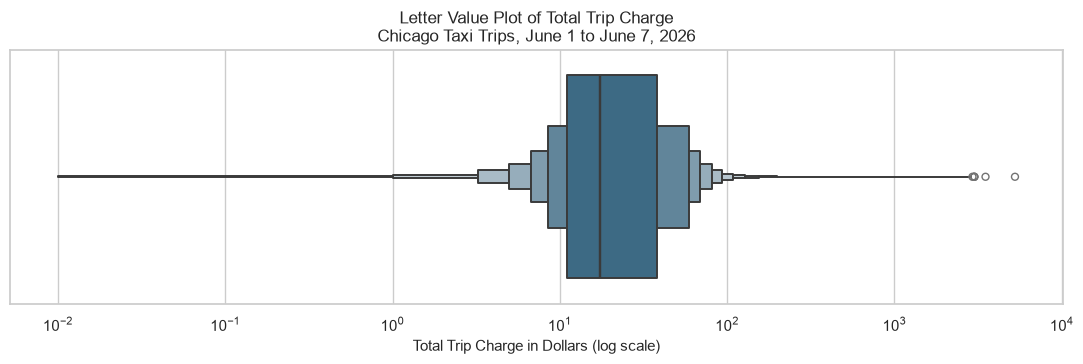

In [11]:
fig, ax = plt.subplots(figsize=(11, 3.8))

sns.boxenplot(
    x=plot_data,
    color="#2a6f97",      # customization 1: color
    saturation=0.65,      # customization 2: saturation
    linewidth=1.4,        # customization 3: line width
    ax=ax,
)

ax.set_xscale("log")
ax.set_xlabel("Total Trip Charge in Dollars (log scale)", fontsize=11)
ax.set_title("Letter Value Plot of Total Trip Charge\n"
             "Chicago Taxi Trips, June 1 to June 7, 2026",
             fontsize=12)
ax.set_yticks([])

plt.tight_layout()
plt.show()

## Visualization 2: Histogram with a KDE line

**Variable:** `trip_minutes`, the trip duration in minutes. This is a different variable
from the letter value plot, as required.

Required elements: a KDE line, a manually specified bin count, density values on the y
axis, and axis labels on both axes.

**Bin choice.** The view is trimmed to trips of 60 minutes or less, which covers roughly
95 percent of the week, and the bin count is set to 60. That puts each bar on a one minute
interval, which is a unit a reader already understands without consulting the axis. The
Freedman Diaconis rule is calculated below as a reference point.

In [12]:
duration = taxi["trip_minutes"].dropna()
window = duration[(duration >= 0) & (duration <= 60)]

print("Trips of 60 minutes or less:", len(window),
      f"({len(window) / len(duration) * 100:.1f} percent of trips with a duration)")

# Freedman Diaconis reference calculation
q1, q3 = window.quantile([0.25, 0.75])
fd_width = 2 * (q3 - q1) / np.cbrt(len(window))
fd_bins = int(np.ceil((window.max() - window.min()) / fd_width))

print()
print(f"Freedman Diaconis bin width: {fd_width:.3f} minutes -> {fd_bins} bins")
print("Bin count chosen for the plot: 60 bins of 1.0 minute each")

Trips of 60 minutes or less: 159673 (95.5 percent of trips with a duration)

Freedman Diaconis bin width: 0.594 minutes -> 102 bins
Bin count chosen for the plot: 60 bins of 1.0 minute each


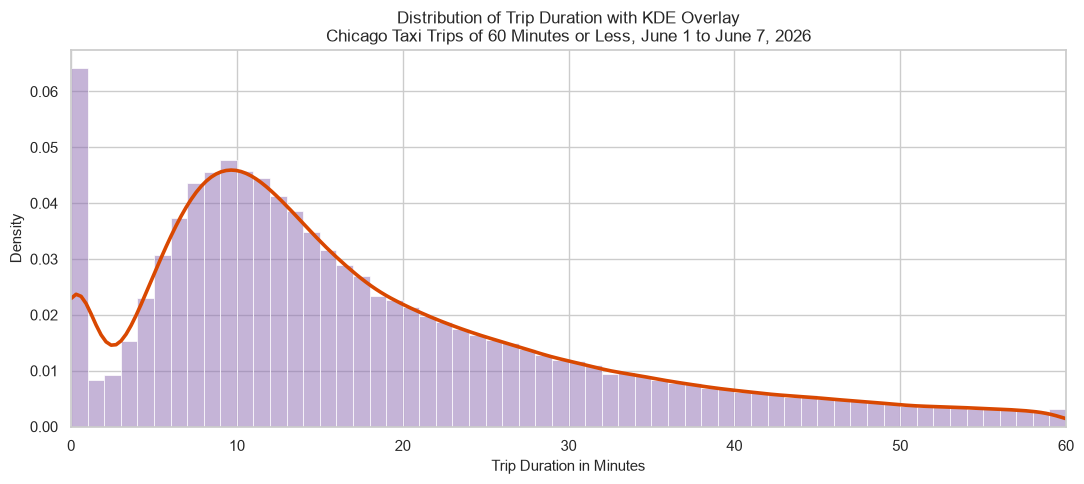

In [13]:
fig, ax = plt.subplots(figsize=(11, 5))

sns.histplot(
    x=window,
    bins=60,              # manually specified bin count
    stat="density",       # density values on the y axis
    kde=True,             # KDE line
    color="#8c6bb1",
    edgecolor="white",
    linewidth=0.5,
    ax=ax,
)

# seaborn draws the KDE using the histogram color, so it is restyled here to
# stand out against the bars
for line in ax.lines:
    line.set_color("#d94801")
    line.set_linewidth(2.6)

ax.set_xlabel("Trip Duration in Minutes", fontsize=11)
ax.set_ylabel("Density", fontsize=11)
ax.set_title("Distribution of Trip Duration with KDE Overlay\n"
             "Chicago Taxi Trips of 60 Minutes or Less, June 1 to June 7, 2026",
             fontsize=12)
ax.set_xlim(0, 60)

plt.tight_layout()
plt.show()

## Visualization 3: Scatter plot

**Variables:** `trip_miles` on the x axis against `fare` on the y axis, split by
`payment_type`. A scatter plot was chosen because it is the only one of the available
graph types that shows two continuous variables against each other rather than
summarizing a single distribution, so it adds a dimension the first two plots cannot.

**Six customization elements:**

1. `hue` mapped to `payment_type` with a hand specified palette
2. `alpha` transparency set to 0.25 to manage overplotting across many points
3. marker size `s` reduced to 10
4. logarithmic scales on both axes
5. a legend with an explicit title, placed in the upper left
6. axis labels, a title, and a dashed reference grid

The three highest volume payment types are shown so the color mapping stays readable.
Log axes require positive values, so records with zero miles or a zero fare are not
plotted, and the counts are printed below.

In [14]:
top_payments = ["Mobile", "Credit Card", "Cash"]

scatter_data = taxi[
    taxi["payment_type"].isin(top_payments)
    & (taxi["trip_miles"] > 0)
    & (taxi["fare"] > 0)
].copy()

print("Records plotted:", len(scatter_data))
print()
print("Excluded from this plot:")
print("  payment type outside the top three:",
      (~taxi["payment_type"].isin(top_payments)).sum())
print("  zero or missing miles:", (~(taxi['trip_miles'] > 0)).sum())
print("  zero or missing fare:  ", (~(taxi['fare'] > 0)).sum())
print()
print(scatter_data["payment_type"].value_counts())

Records plotted: 141200

Excluded from this plot:
  payment type outside the top three: 12990
  zero or missing miles: 13182
  zero or missing fare:   657

payment_type
Mobile         65440
Credit Card    50690
Cash           25070
Name: count, dtype: int64


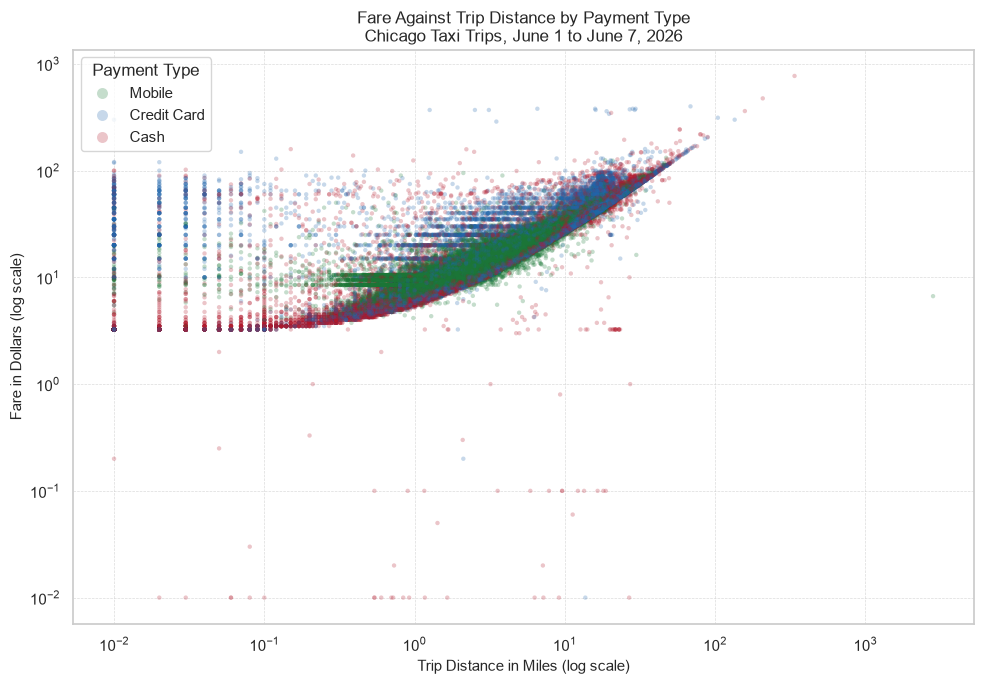

In [15]:
palette = {"Mobile": "#1b7837", "Credit Card": "#2166ac", "Cash": "#b2182b"}

fig, ax = plt.subplots(figsize=(10, 7))

sns.scatterplot(
    data=scatter_data,
    x="trip_miles",
    y="fare",
    hue="payment_type",
    hue_order=top_payments,
    palette=palette,       # customization 1
    alpha=0.25,            # customization 2
    s=10,                  # customization 3
    edgecolor="none",
    ax=ax,
)

ax.set_xscale("log")       # customization 4
ax.set_yscale("log")
ax.set_xlabel("Trip Distance in Miles (log scale)", fontsize=11)
ax.set_ylabel("Fare in Dollars (log scale)", fontsize=11)
ax.set_title("Fare Against Trip Distance by Payment Type\n"
             "Chicago Taxi Trips, June 1 to June 7, 2026",
             fontsize=12)

legend = ax.legend(title="Payment Type", loc="upper left",   # customization 5
                   frameon=True, markerscale=2.5)
ax.grid(True, which="major", linestyle="--", linewidth=0.5, alpha=0.7)  # customization 6

plt.tight_layout()
plt.show()

## Notes on the three selections

**Letter value plot, `trip_total`.** A letter value plot is built for exactly this
situation: a large sample with a long right tail. With 167,303 records a standard boxplot
would draw several thousand individual points past the whiskers and the figure would be
unreadable, whereas the letter value plot keeps subdividing the tail into successively
smaller boxes and shows its shape instead. `trip_total` is also the most heavily skewed
numeric column in the file, running from 0 to 5,250 dollars with a median near 17, so it
gives the technique the most to work with.

**Histogram with KDE, `trip_minutes`.** Duration was the natural second choice because it
is continuous, it is on a scale readers have intuition about, and it is independent of the
dollar amounts used in the first plot. I settled on 60 bins over a 0 to 60 minute window
so that each bar covers exactly one minute. The Freedman Diaconis rule suggests a
count of 102, which works out to a bin width of 0.59 minutes. A one minute bin is far
easier to explain to an audience than a 35 second bin, and at this sample size the
histogram shape is stable either way. Seaborn draws the KDE using the same color as the
bars, so the line is restyled in orange afterward to keep it readable.

**Scatter plot, `fare` against `trip_miles`.** The first two plots each describe one
variable at a time. A scatter plot was the only remaining option that puts two continuous
variables in the same frame, which is why I chose it over a violin plot or a bar chart
that would have repeated what the letter value plot already covers. Splitting by
`payment_type` adds a categorical dimension at no cost. Log scales on both axes were
necessary rather than decorative, since distance and fare each span several orders of
magnitude, and low alpha with small markers keeps a dense cloud of points from turning
into a solid block.

## Reference

[1] City of Chicago, "Taxi Trips (2024- )," Chicago Data Portal, updated Sep. 10, 2026.
[Online]. Available: https://data.cityofchicago.org/Transportation/Taxi-Trips-2024-/ajtu-isnz